In [1]:
import pandas
import seaborn
from matplotlib import pyplot
from pandas.plotting import register_matplotlib_converters

from airpollutionforecasting.pipeline import run_pipeline
from airpollutionforecasting.eda.ts_correlation import TSCorrelationChecker

register_matplotlib_converters()
seaborn.set_style("darkgrid")

2026-11-18 21:55:07.682 | INFO     | airpollutionforecasting.config:<module>:18 - PROJ_ROOT path is: /home/pabito/Desktop/Projects/AirPolutionForecasting


In [2]:
pyplot.rc("figure", figsize=(16, 12))
pyplot.rc("font", size=13)

In [2]:
# run the pipeline to get the location of splitted files
split_files_locations = run_pipeline(stop_step="split")
# load the training data
data = pandas.read_csv(split_files_locations[0])
data["time"] = pandas.to_datetime(data["time"])

2026-11-18 21:55:09.800 | INFO     | airpollutionforecasting.pipeline:run_pipeline:28 - Running pipeline until split...
2026-11-18 21:55:09.802 | INFO     | airpollutionforecasting.data.loader:load:20 - Loading the data..
2026-11-18 21:55:09.895 | INFO     | airpollutionforecasting.data.data_validator:validate:149 - Starting data validation...
2026-11-18 21:55:09.895 | INFO     | airpollutionforecasting.data.data_validator:validate:151 - Checking required columns and data types...
2026-11-18 21:55:09.896 | SUCCESS  | airpollutionforecasting.data.data_validator:validate:153 - Column and data type validation passed.
2026-11-18 21:55:09.896 | INFO     | airpollutionforecasting.data.data_validator:validate:155 - Checking configured date range...
2026-11-18 21:55:09.897 | SUCCESS  | airpollutionforecasting.data.data_validator:validate:157 - Date range validation passed.
2026-11-18 21:55:09.897 | INFO     | airpollutionforecasting.data.data_validator:validate:159 - Checking for missing value

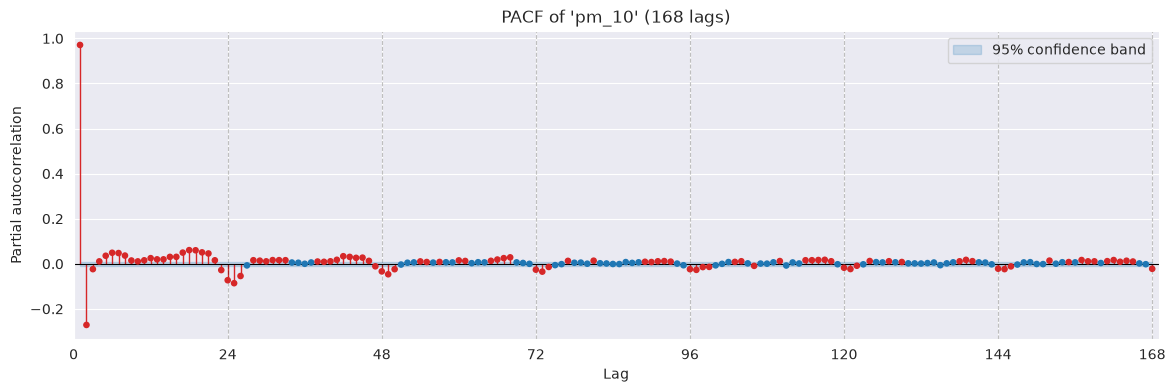

In [3]:
checker = TSCorrelationChecker(data, target_col="pm_10")

checker.plot_pacf_graph(
    nlags=168, seasonal_period=24
)  # daily guide lines every 24 lags
pyplot.show()

In [5]:
pacf_df = checker.calculate_pacf(nlags=168)

# Significant lags, strongest first
pacf_df[pacf_df["significant"]].sort_values("pacf", key=abs, ascending=False).head(10)

,pacf,lower,upper,significant
lag,,,,
1,0.971045,-0.007667,0.007667,True
2,-0.271400,-0.007667,0.007667,True
25,-0.086156,-0.007667,0.007667,True
24,-0.072964,-0.007667,0.007667,True
18,0.060560,-0.007667,0.007667,True
19,0.059914,-0.007667,0.007667,True
26,-0.054312,-0.007667,0.007667,True
20,0.050683,-0.007667,0.007667,True
17,0.049596,-0.007667,0.007667,True


In [6]:
acf_df = checker.calculate_acf(nlags=168)

acf_df[acf_df["significant"] & (acf_df["acf"].abs() > 0.1)]

/home/pabito/Desktop/Projects/AirPolutionForecasting/airpollutionforecasting/eda/ts_correlation.py:184: FutureWarning: acf currently returns a plain tuple whose length depends on the qstat and alpha arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an AcfResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  values, confint = acf(


,acf,lower,upper,significant
lag,,,,
1,0.971060,-0.007667,0.007667,True
2,0.927467,-0.013024,0.013024,True
3,0.880243,-0.016455,0.016455,True
4,0.834050,-0.019022,0.019022,True
5,0.791794,-0.021063,0.021063,True
...,...,...,...,...
164,0.247887,-0.055504,0.055504,True
165,0.259877,-0.055569,0.055569,True
166,0.271051,-0.055641,0.055641,True


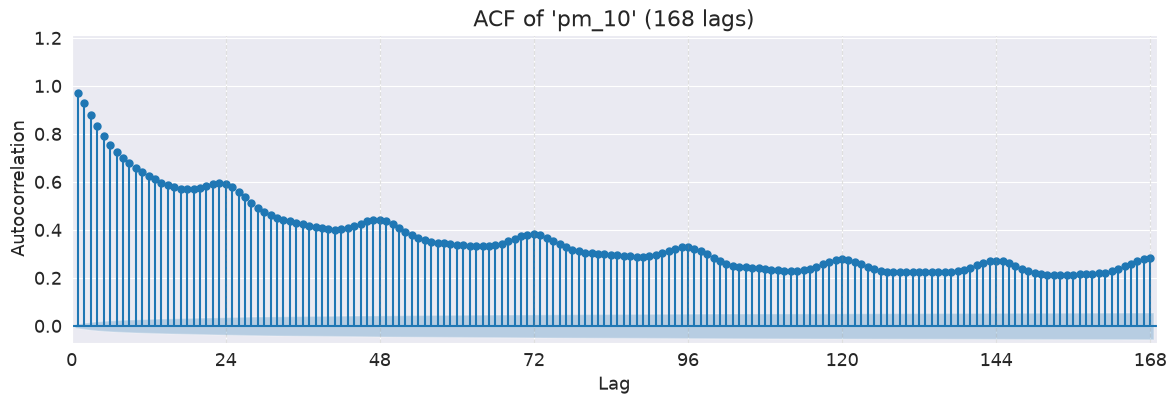

In [8]:
checker.plot_acf_graph(nlags=168)
pyplot.show()

In [7]:
ccf = checker.calculate_ccf(["air_temp", "relative_humidity", "wind_speed"], max_lag=72)

# Strongest lag per covariate
ccf.abs().idxmax()  # lag with the largest |correlation|
ccf.loc[ccf.abs().idxmax()]  # hmm, or simply:
ccf.apply(lambda s: s.loc[s.abs().idxmax()])  # its value

# Only lags usable by a past covariate with a 24h horizon
ccf.loc[24:]

# Same-time correlation (relevant for future covariates)
ccf.loc[0]

air_temp            -0.386207
relative_humidity    0.124240
wind_speed          -0.254733
Name: 0, dtype: float64

In [10]:
# Only lags usable by a past covariate with a 24h horizon
ccf.loc[24:]

,air_temp,relative_humidity,wind_speed
lag,,,
24,-0.402383,0.104348,-0.186855
25,-0.406349,0.112245,-0.194082
26,-0.407891,0.115383,-0.198023
27,-0.406186,0.112139,-0.196935
28,-0.401095,0.102620,-0.189230
29,-0.393278,0.088186,-0.175300
30,-0.383845,0.070821,-0.157581
31,-0.374132,0.052648,-0.138241
32,-0.365257,0.035665,-0.119452


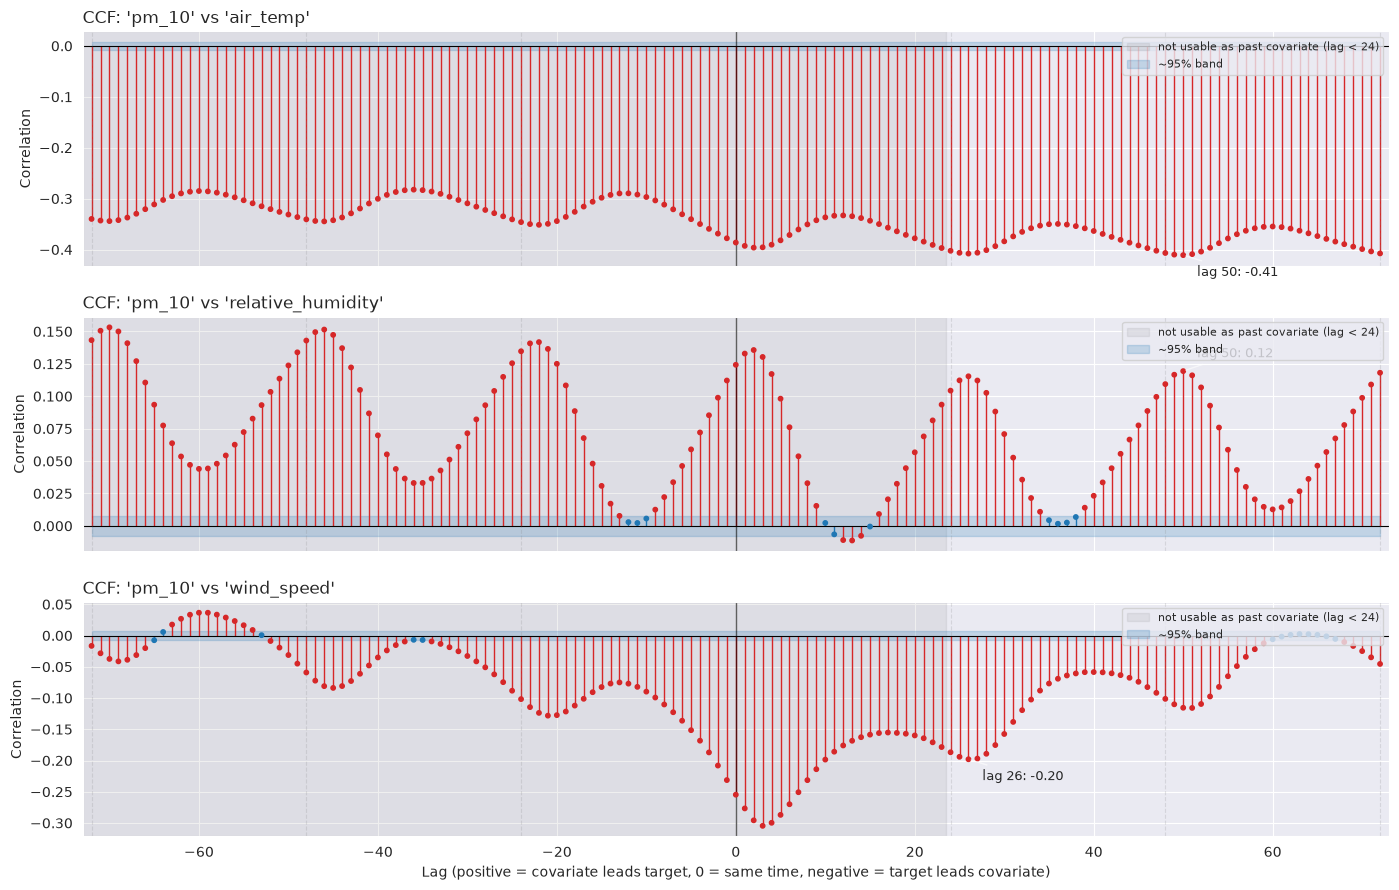

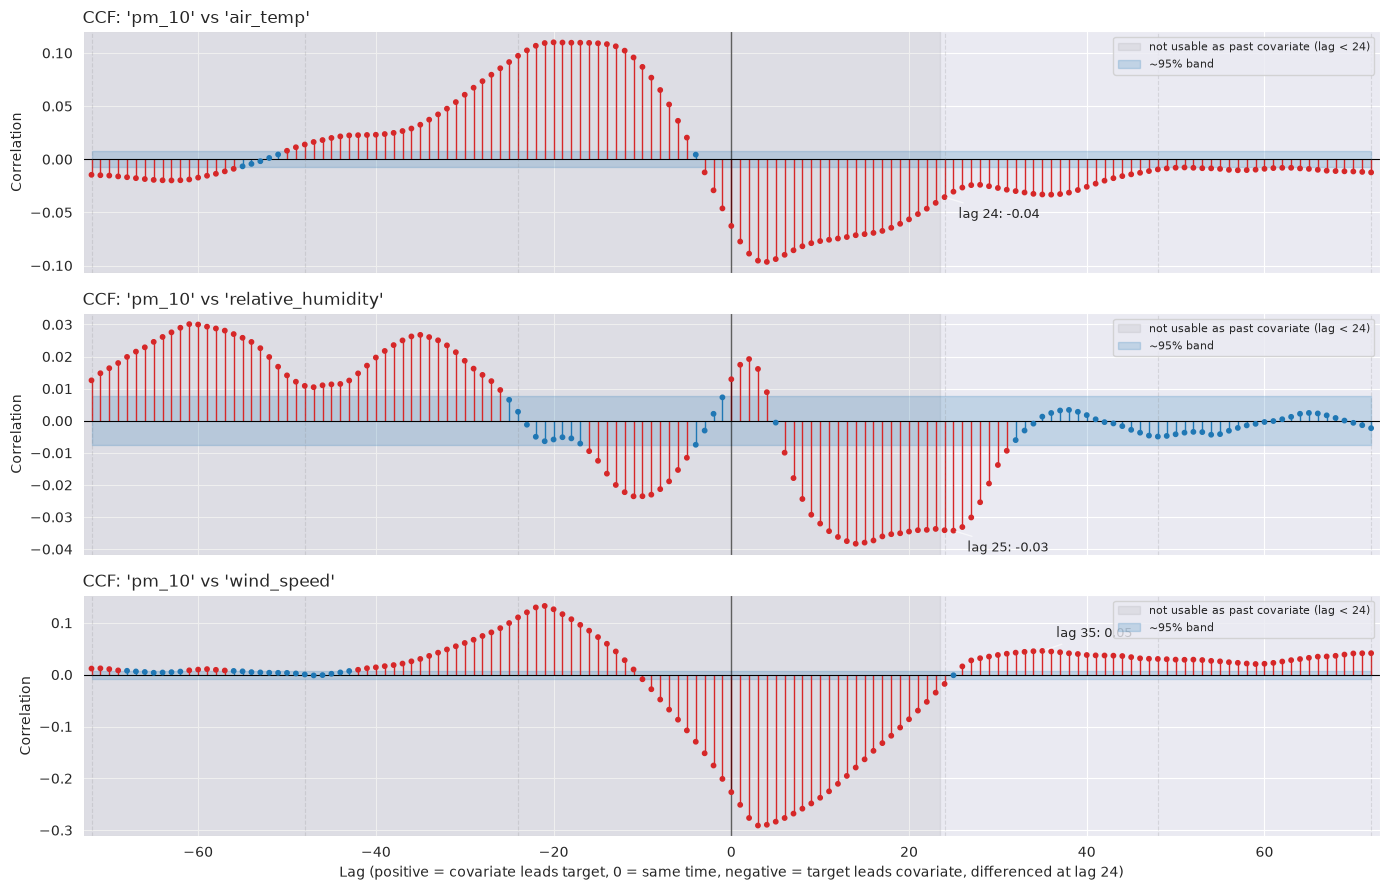

In [6]:
# Raw vs differenced, 24h forecast horizon
checker.plot_ccf(
    ["air_temp", "relative_humidity", "wind_speed"], max_lag=72, horizon=24
)
checker.plot_ccf(
    ["air_temp", "relative_humidity", "wind_speed"], max_lag=72, horizon=24, diff_lag=24
)
pyplot.show()